# Etapa 2 — Análise exploratória dos dados

**Projeto:** previsão da volatilidade do Ibovespa (GARCH, HAR e random forest)
**Curso:** Introdução à Modelagem Econômica e Ciência de Dados — UFJF, 2026

Este notebook descreve os dados antes de qualquer modelo. Ele responde a cinco perguntas:

1. Os dados estão em ordem? (seção 1)
2. Como se comportam os retornos do Ibovespa? (seções 2 e 3)
3. Como se comporta a volatilidade que queremos prever? (seções 4 e 5)
4. O estimador de Garman-Klass e o retorno ao quadrado medem a mesma coisa? (seção 6). A resposta decide como comparar o GARCH com os outros modelos.
5. Os preditores exógenos se relacionam com a volatilidade futura? (seção 7)

**Como rodar:** a partir da pasta do projeto, depois de `python src/coleta_dados.py`. O notebook recalcula as variáveis com `src/features.py`, então não depende de `features.csv`. As figuras são salvas em `figuras/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf, adfuller

# Pasta do projeto: funciona rodando de notebooks/ ou da raiz.
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import features as F  # noqa: E402

PASTA_FIG = RAIZ / "figuras"
PASTA_FIG.mkdir(exist_ok=True)

# Períodos de estresse da hipótese H3, tomados literalmente como anos-calendário.
ESTRESSE = {"2008": ("2008-01-01", "2008-12-31"),
            "2015–2016": ("2015-01-01", "2016-12-31"),
            "2020": ("2020-01-01", "2020-12-31")}

# Visual: cores fixas por papel, marcas finas, grade discreta.
AZUL, LARANJA, CINZA, SOMBRA = "#2a78d6", "#eb6834", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": CINZA, "axes.labelcolor": "#0b0b0b",
    "xtick.color": CINZA, "ytick.color": CINZA, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 1.2,
})

def sombrear_estresse(ax):
    # Faixas cinza nos períodos de estresse.
    for ini, fim in ESTRESSE.values():
        ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fim), color=SOMBRA, zorder=0, lw=0)

def salvar(fig, nome):
    fig.savefig(PASTA_FIG / f"{nome}.png", bbox_inches="tight")

def em_estresse(indice):
    m = pd.Series(False, index=indice)
    for ini, fim in ESTRESSE.values():
        m |= (indice >= ini) & (indice <= fim)
    return m

## 1. A base de dados

A base vem de `src/coleta_dados.py` (Yahoo Finance, BCB e FRED). As variáveis vêm de `src/features.py`. Ele roda verificações automáticas contra viés de antecipação, isto é, contra o uso acidental de informação do futuro.

In [2]:
base = pd.read_csv(RAIZ / "data" / "processed" / "dados_mercado.csv", index_col="data", parse_dates=["data"])
feats = F.construir_features(base)
for item in F.verificar(base, feats):
    print("OK -", item)

print()
print((RAIZ / "data" / "coleta_log.txt").read_text(encoding="utf-8"))

qualidade = pd.Series({
    "Dias de negociação": len(base),
    "Preços inconsistentes (ohlc_invalido)": int(feats["ohlc_invalido"].sum()),
    "Amplitude zero (máxima = mínima)": int(feats["amplitude_zero"].sum()),
    "Picos suspeitos (regra revisada)": int(feats["pico_suspeito"].sum()),
}, name="quantidade")
qualidade.to_frame()

OK - variância de Garman-Klass nunca negativa
OK - preditores idênticos quando a base é cortada (não usam dados futuros)
OK - alvos = média de t+1 a t+h (50 datas sorteadas) e vazios nas últimas h linhas
OK - componente diário do HAR = volatilidade do dia

Data da coleta (acesso): 24/10/2026
Período da base: 2000-01-03 a 2026-10-23
Observações (dias de negociação da B3): 6644
Linhas com preços inconsistentes (sinalizadas, não removidas): 0
Dias da B3 sem observação própria na série (preenchidos com a última disponível):
  - ptax_venda: 0
  - selic_meta: 0
  - vix: 141
Linhas ainda com algum valor ausente (início da amostra): 0



,quantidade
Dias de negociação,6644
Preços inconsistentes (ohlc_invalido),0
Amplitude zero (máxima = mínima),0
Picos suspeitos (regra revisada),3


### 1.1 Picos suspeitos: as duas regras

A regra para separar **possíveis erros de dado** foi revisada depois de ver os casos. Os dois critérios estão abaixo, por transparência.

- **Regra original**, definida antes de olhar os dados: amplitude do dia, ln(máxima/mínima), maior que 5 vezes a mediana dos 20 vizinhos.
- **Regra revisada**, desenhada depois de ver os casos: amplitude maior que 3 vezes a dos vizinhos **e** corpo do dia, |ln(fechamento/abertura)|, menor que 10% da amplitude.

A ideia da revisão: num choque real, o preço anda e fica lá, e o corpo ocupa quase toda a amplitude. Num erro de dado, aparece uma máxima ou mínima extrema e o dia fecha quase onde abriu.

Os dias marcados **não são alterados**. A análise principal usa os valores originais, e a exclusão desses dias fica como teste de robustez na Etapa 3.

In [3]:
regra_original = feats["razao_amplitude"] > 5
tabela_picos = feats.loc[regra_original | feats["pico_suspeito"], ["razao_amplitude", "corpo_amplitude", "vol_gk"]].copy()
tabela_picos["retorno_dia_%"] = 100 * base["retorno_log"]
tabela_picos["regra_original"] = regra_original
tabela_picos["regra_revisada"] = feats["pico_suspeito"]
tabela_picos["corpo_amplitude"] *= 100
tabela_picos.round(2).rename(columns={"corpo_amplitude": "corpo_%_amplitude", "vol_gk": "vol_GK_%aa"})

,razao_amplitude,corpo_%_amplitude,vol_GK_%aa,retorno_dia_%,regra_original,regra_revisada
data,,,,,,
2000-11-24,4.23,1.32,118.49,0.15,False,True
2000-12-18,3.13,6.65,90.76,0.63,False,True
2001-03-20,3.14,3.27,113.08,0.45,False,True
2017-05-18,6.86,81.40,88.68,-9.21,True,False
2026-10-05,5.88,85.13,64.79,7.42,True,False


## 2. Retornos do Ibovespa

O retorno diário é o log-retorno do fechamento: r_t = ln(P_t / P_{t-1}). Duas perguntas guiam esta seção. A distribuição é parecida com a normal? Existem mais dias extremos do que a normal preveria?

In [4]:
r = base["retorno_log"].dropna()
jb = stats.jarque_bera(r)
z = (r - r.mean()) / r.std()
esperado_normal = len(r) * 2 * stats.norm.sf(4)

desc_ret = pd.Series({
    "Observações": len(r),
    "Média diária (%)": 100 * r.mean(),
    "Desvio-padrão diário (%)": 100 * r.std(),
    "Volatilidade anualizada (%)": 100 * r.std() * np.sqrt(252),
    "Assimetria": stats.skew(r),
    "Curtose em excesso": stats.kurtosis(r),
    "Mínimo (%)": 100 * r.min(),
    "Máximo (%)": 100 * r.max(),
    "Jarque-Bera (estatística)": jb.statistic,
    "Jarque-Bera (p-valor)": jb.pvalue,
    "Dias com |z| > 4": int((z.abs() > 4).sum()),
    "Dias com |z| > 4 esperados sob a normal": esperado_normal,
}, name="retorno log diário")
desc_ret.round(4).to_frame()

,retorno log diário
Observações,6643.0000
Média diária (%),0.0375
Desvio-padrão diário (%),1.6912
Volatilidade anualizada (%),26.8468
Assimetria,-0.3352
Curtose em excesso,7.0484
Mínimo (%),-15.9930
Máximo (%),13.6766
Jarque-Bera (estatística),13875.3984
Jarque-Bera (p-valor),0.0000


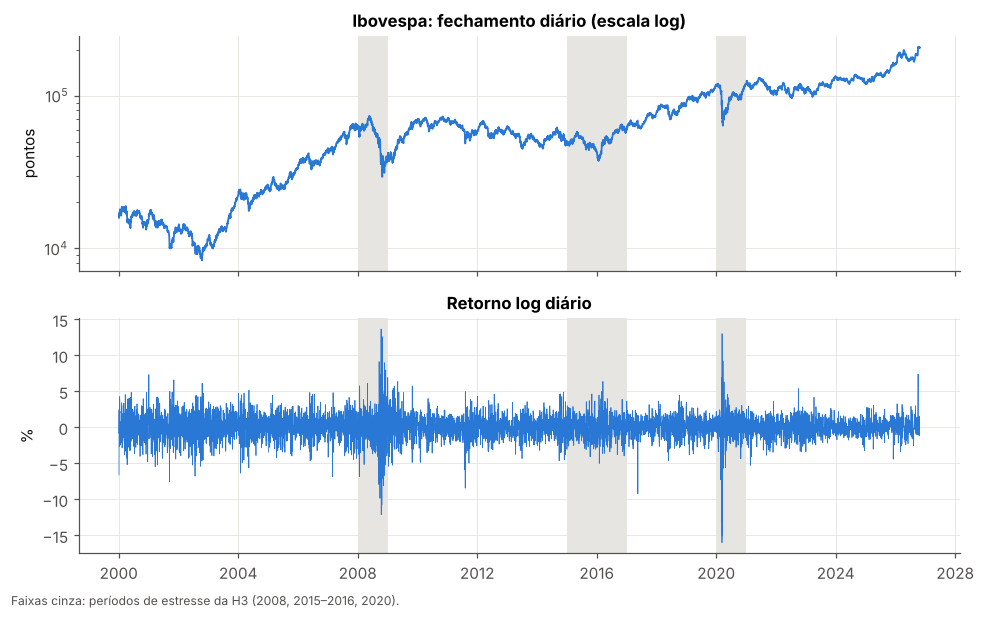

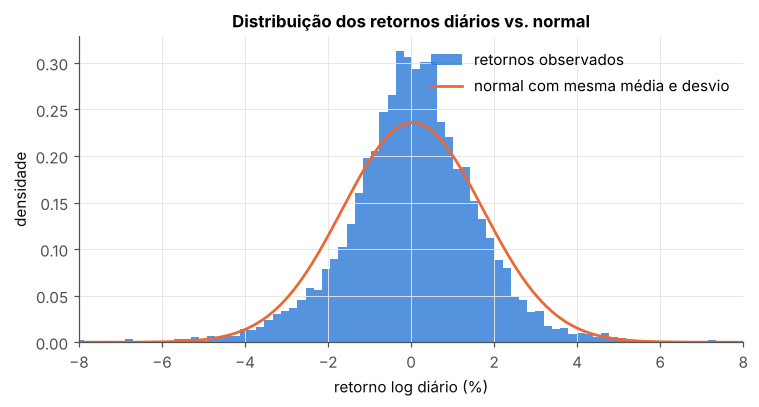

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, height_ratios=[1, 1])
ax1.plot(base.index, base["fechamento"], color=AZUL)
ax1.set_yscale("log")
ax1.set_title("Ibovespa: fechamento diário (escala log)")
ax1.set_ylabel("pontos")
ax2.plot(r.index, 100 * r, color=AZUL, lw=0.5)
ax2.set_title("Retorno log diário")
ax2.set_ylabel("%")
for ax in (ax1, ax2):
    sombrear_estresse(ax)
fig.text(0.01, -0.01, "Faixas cinza: períodos de estresse da H3 (2008, 2015–2016, 2020).", color=CINZA, fontsize=8)
fig.tight_layout()
salvar(fig, "eda_01_ibovespa_retornos")
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(100 * r, bins=150, density=True, color=AZUL, alpha=0.8, label="retornos observados")
x = np.linspace(100 * r.min(), 100 * r.max(), 500)
ax.plot(x, stats.norm.pdf(x, 100 * r.mean(), 100 * r.std()), color=LARANJA, lw=1.8, label="normal com mesma média e desvio")
ax.set_xlim(-8, 8)
ax.set_title("Distribuição dos retornos diários vs. normal")
ax.set_xlabel("retorno log diário (%)")
ax.set_ylabel("densidade")
ax.legend(frameon=False)
fig.tight_layout()
salvar(fig, "eda_02_histograma_retornos")
plt.show()

**Leitura (rascunho):**
- A distribuição tem **caudas grossas**: a curtose em excesso é bem maior que zero (zero é o valor da normal). Há dezenas de dias com |z| > 4, contra menos de um esperado sob a normal. O teste de Jarque-Bera rejeita a normalidade.
- A assimetria é negativa: as quedas extremas são maiores que as altas extremas.
- No gráfico de retornos, os dias agitados aparecem **agrupados no tempo**, e não espalhados ao acaso. A próxima seção mede isso.

## 3. Agrupamento de volatilidade

A **autocorrelação** mede quanto o valor de hoje se parece com o de k dias atrás. Comparamos duas séries:

- **retornos:** se fossem previsíveis, a autocorrelação seria alta. A expectativa é que seja próxima de zero;
- **retornos ao quadrado:** medem o tamanho do movimento, sem o sinal. Se dias agitados seguem dias agitados, a autocorrelação é positiva e persistente.

Esse padrão (*volatility clustering*) é a razão de existirem modelos como o GARCH e o HAR. O teste de Ljung-Box verifica se as autocorrelações, em conjunto, são diferentes de zero.

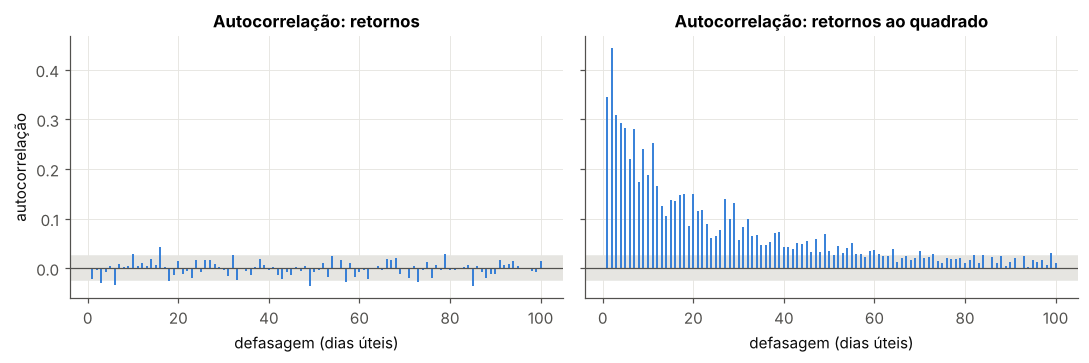

lb_stat  lb_pvalue
série                defasagens                      
retornos             5              9.5495     0.0891
                     22            47.5417     0.0012
retornos ao quadrado 5           3830.9915     0.0000
                     22          7202.3160     0.0000

In [6]:
LAGS = 100
acf_r = acf(r, nlags=LAGS)
acf_r2 = acf(r**2, nlags=LAGS)
banda = 1.96 / np.sqrt(len(r))  # faixa aproximada de 95% para "zero"

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, valores, titulo in [(axs[0], acf_r, "Retornos"), (axs[1], acf_r2, "Retornos ao quadrado")]:
    ax.vlines(range(1, LAGS + 1), 0, valores[1:], color=AZUL, lw=1.2)
    ax.axhspan(-banda, banda, color=SOMBRA, zorder=0)
    ax.axhline(0, color=CINZA, lw=0.8)
    ax.set_title(f"Autocorrelação: {titulo.lower()}")
    ax.set_xlabel("defasagem (dias úteis)")
axs[0].set_ylabel("autocorrelação")
fig.tight_layout()
salvar(fig, "eda_03_acf_retornos")
plt.show()

lb = pd.concat({
    "retornos": acorr_ljungbox(r, lags=[5, 22], return_df=True),
    "retornos ao quadrado": acorr_ljungbox(r**2, lags=[5, 22], return_df=True),
})
lb.index.names = ["série", "defasagens"]
lb.round(4)

**Leitura (rascunho):**
- A autocorrelação dos retornos é pequena, mas não exatamente zero. Com 22 defasagens, o Ljung-Box rejeita a hipótese de autocorrelação nula. Numa amostra de mais de 6 mil dias, até correlações muito pequenas ficam estatisticamente significativas.
- A diferença de escala é o que importa: a estatística de Ljung-Box dos retornos ao quadrado é centenas de vezes maior que a dos retornos.
- Ou seja, **a direção do mercado é difícil de prever, mas o tamanho dos movimentos é persistente.** É isso que torna a volatilidade previsível e justifica o projeto.

## 4. A volatilidade de Garman-Klass (o alvo)

O estimador de Garman e Klass (1980) usa abertura, máxima, mínima e fechamento para estimar a variância de cada dia. A série abaixo é a volatilidade anualizada em %, 100·√(252·σ²), a unidade aprovada para o alvo.

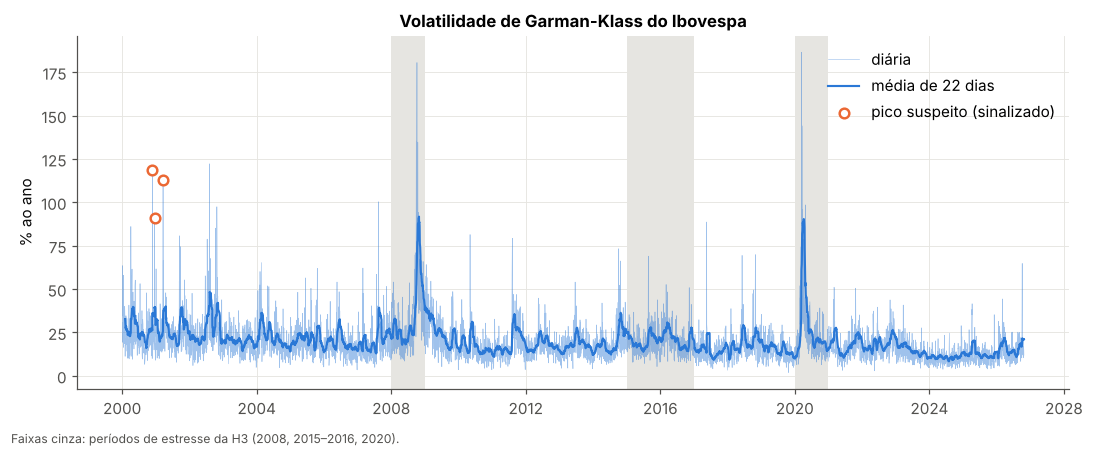

,vol GK (% a.a.),log da vol GK
count,6644.000,6644.000
mean,18.984,2.817
std,11.507,0.486
min,1.904,0.644
5%,7.852,2.061
50%,16.621,2.811
95%,37.146,3.615
max,186.528,5.229
assimetria,3.910,0.284


In [7]:
vol = feats["vol_gk"]
fig, ax = plt.subplots(figsize=(10, 4))
sombrear_estresse(ax)
ax.plot(vol.index, vol, color=AZUL, lw=0.4, alpha=0.45, label="diária")
ax.plot(feats.index, feats["har_m"], color=AZUL, lw=1.4, label="média de 22 dias")
picos = feats.index[feats["pico_suspeito"]]
ax.scatter(picos, vol.loc[picos], s=40, facecolor="white", edgecolor=LARANJA, lw=1.6, zorder=5, label="pico suspeito (sinalizado)")
ax.set_title("Volatilidade de Garman-Klass do Ibovespa")
ax.set_ylabel("% ao ano")
ax.legend(frameon=False, loc="upper right")
fig.text(0.01, -0.02, "Faixas cinza: períodos de estresse da H3 (2008, 2015–2016, 2020).", color=CINZA, fontsize=8)
fig.tight_layout()
salvar(fig, "eda_04_vol_gk_serie")
plt.show()

log_vol = np.log(vol)
desc_vol = pd.DataFrame({
    "vol GK (% a.a.)": vol.describe(percentiles=[0.05, 0.5, 0.95]),
    "log da vol GK": log_vol.describe(percentiles=[0.05, 0.5, 0.95]),
})
desc_vol.loc["assimetria"] = [stats.skew(vol), stats.skew(log_vol)]
desc_vol.round(3)

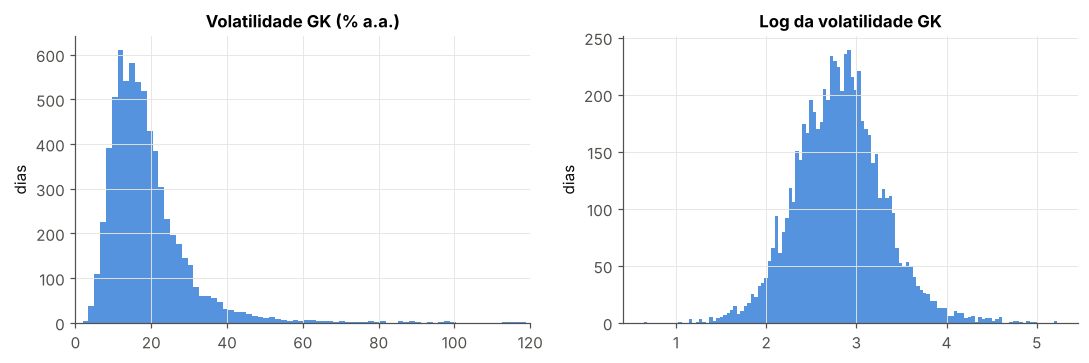

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].hist(vol, bins=120, color=AZUL, alpha=0.8)
axs[0].set_title("Volatilidade GK (% a.a.)")
axs[0].set_xlim(0, 120)
axs[1].hist(log_vol, bins=120, color=AZUL, alpha=0.8)
axs[1].set_title("Log da volatilidade GK")
for ax in axs:
    ax.set_ylabel("dias")
fig.tight_layout()
salvar(fig, "eda_05_distribuicao_vol")
plt.show()

### 4.1 Memória longa e estacionariedade

O HAR de Corsi (2009) parte da ideia de que a volatilidade tem **memória longa**: o passado distante ainda importa, mas cada vez menos. Por isso o modelo usa médias de 1, 5 e 22 dias. Se for verdade, a autocorrelação da volatilidade cai devagar, ao longo de meses.

O teste ADF (Dickey-Fuller aumentado) verifica se a série é **estacionária**, isto é, se oscila em torno de uma média estável em vez de "passear" sem rumo. Rejeitar a hipótese nula do ADF indica estacionariedade. Isso é importante para que um modelo estimado no passado valha no futuro.

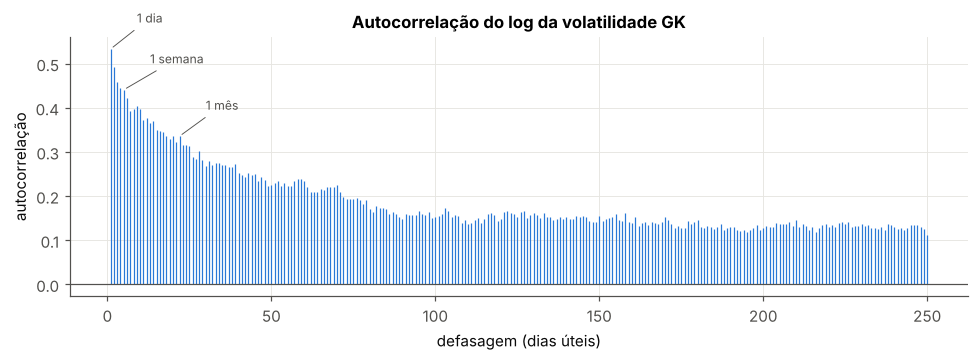

,vol GK,log vol GK
defasagem,,
1,0.580,0.533
5,0.488,0.441
22,0.296,0.336
66,0.161,0.214
125,0.083,0.152
250,0.055,0.111


ADF no log da vol GK: estatística = -7.17; p-valor = 0.0000; defasagens usadas = 27


In [9]:
LAGS_V = 250
acf_v = acf(log_vol, nlags=LAGS_V)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.vlines(range(1, LAGS_V + 1), 0, acf_v[1:], color=AZUL, lw=0.8)
for k, nome in [(1, "1 dia"), (5, "1 semana"), (22, "1 mês")]:
    ax.annotate(nome, (k, acf_v[k]), xytext=(k + 8, acf_v[k] + 0.06), fontsize=8, color=CINZA,
                arrowprops=dict(arrowstyle="-", color=CINZA, lw=0.6))
ax.axhline(0, color=CINZA, lw=0.8)
ax.set_title("Autocorrelação do log da volatilidade GK")
ax.set_xlabel("defasagem (dias úteis)")
ax.set_ylabel("autocorrelação")
fig.tight_layout()
salvar(fig, "eda_06_acf_vol")
plt.show()

tab_acf = pd.DataFrame({"vol GK": acf(vol, nlags=LAGS_V), "log vol GK": acf_v}).loc[[1, 5, 22, 66, 125, 250]]
tab_acf.index.name = "defasagem"
display(tab_acf.round(3))

adf = adfuller(log_vol, autolag="AIC", result_object=False)
print(f"ADF no log da vol GK: estatística = {adf[0]:.2f}; p-valor = {adf[1]:.4f}; defasagens usadas = {adf[2]}")

## 5. Volatilidade por ano e períodos de estresse

A H3 diz que o ganho do ML se concentra em 2008, 2015–2016 e 2020. Antes de testar isso (Etapa 3), vale conferir se esses anos foram, de fato, de volatilidade alta no Ibovespa.

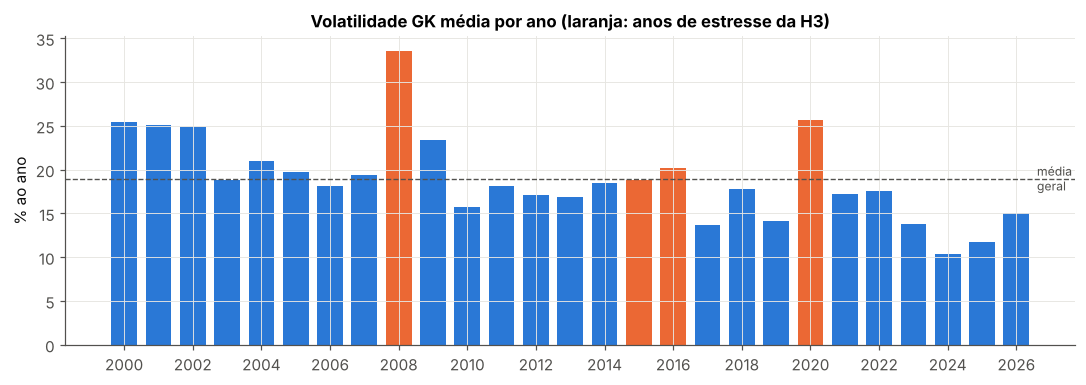

,vol GK média (% a.a.)
2008,33.5
2015–2016,19.5
2020,25.7
Todos os períodos de estresse,24.6
Demais dias (calma),18.0
Amostra toda,19.0


In [10]:
por_ano = vol.groupby(vol.index.year).mean()
anos_estresse = {2008, 2015, 2016, 2020}
cores = [LARANJA if a in anos_estresse else AZUL for a in por_ano.index]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(por_ano.index, por_ano.values, color=cores, width=0.75)
ax.axhline(vol.mean(), color=CINZA, lw=0.9, ls="--")
ax.text(por_ano.index[-1] + 0.6, vol.mean(), "média\ngeral", va="center", fontsize=8, color=CINZA)
ax.set_title("Volatilidade GK média por ano (laranja: anos de estresse da H3)")
ax.set_ylabel("% ao ano")
ax.set_xticks(por_ano.index[::2])
fig.tight_layout()
salvar(fig, "eda_07_vol_por_ano")
plt.show()

estresse = em_estresse(feats.index)
linhas = {nome: vol.loc[ini:fim].mean() for nome, (ini, fim) in ESTRESSE.items()}
linhas["Todos os períodos de estresse"] = vol[estresse].mean()
linhas["Demais dias (calma)"] = vol[~estresse].mean()
linhas["Amostra toda"] = vol.mean()
pd.Series(linhas, name="vol GK média (% a.a.)").round(1).to_frame()

## 6. Garman-Klass vs. retorno ao quadrado (decisão b)

O GARCH é estimado com o retorno de fechamento a fechamento. Portanto, ele prevê a variância **do retorno ao quadrado**. O alvo do projeto é a variância de **Garman-Klass**. Se as duas medidas tiverem níveis diferentes, o GARCH erra por causa da unidade, e não por falta de qualidade.

A hipótese da Etapa 1 era que a diferença viria do **salto noturno**, o movimento entre o fechamento de ontem e a abertura de hoje, que o Garman-Klass ignora. Para testar, o retorno do dia é decomposto em duas partes:

- **noturno:** ln(abertura_t / fechamento_{t−1});
- **intradiário:** ln(fechamento_t / abertura_t).

In [11]:
noturno = np.log(base["abertura"] / base["fechamento"].shift(1))
intradiario = np.log(base["fechamento"] / base["abertura"])
r2 = base["retorno_log"] ** 2

def comparar(periodo):
    s = slice(*periodo)
    vg, vr = feats["var_gk"].loc[s].mean(), r2.loc[s].mean()
    return pd.Series({
        "vol GK, da variância média (% a.a.)": 100 * np.sqrt(252 * vg),
        "vol do retorno, da variância média (% a.a.)": 100 * np.sqrt(252 * vr),
        "razão das variâncias: retorno² / GK": vr / vg,
        "parte noturna da variância do retorno (%)": 100 * (noturno**2).loc[s].mean() / vr,
        "parte intradiária da variância do retorno (%)": 100 * (intradiario**2).loc[s].mean() / vr,
    })

tab_gk = pd.DataFrame({
    "amostra toda": comparar((None, None)),
    "treino (2000–2006)": comparar(("2000", "2006")),
    "teste (2007–2026)": comparar(("2007", None)),
})
# Nota: aqui a vol vem da variância média do período. Por isso fica acima da média
# das vols diárias da seção 5: a raiz da média é maior que a média das raízes.
tab_gk.round(3)

,amostra toda,treino (2000–2006),teste (2007–2026)
"vol GK, da variância média (% a.a.)",22.199,24.443,21.349
"vol do retorno, da variância média (% a.a.)",26.851,29.000,26.050
razão das variâncias: retorno² / GK,1.463,1.408,1.489
parte noturna da variância do retorno (%),0.861,2.280,0.239
parte intradiária da variância do retorno (%),98.597,97.147,99.229


Dias em que a abertura é igual ao fechamento anterior: 23.5%
Tamanho médio do salto noturno nos demais dias: 3.6 pontos-base (0,01%)


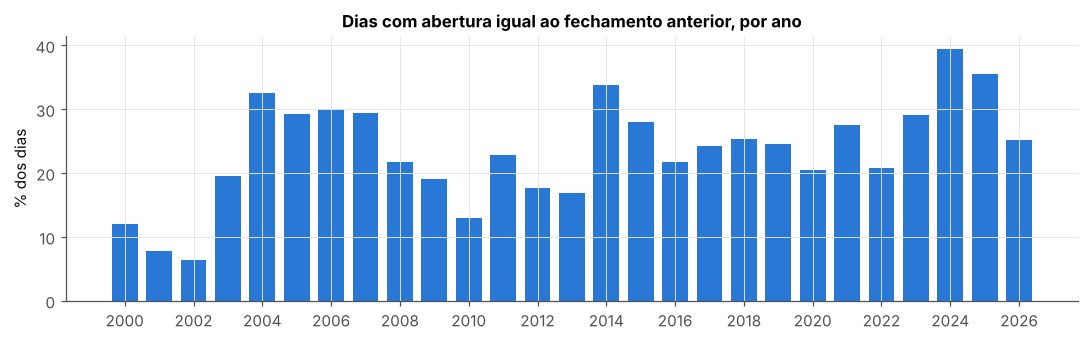

In [12]:
abre_igual = base["abertura"] == base["fechamento"].shift(1)
print(f"Dias em que a abertura é igual ao fechamento anterior: {100 * abre_igual.mean():.1f}%")
print(f"Tamanho médio do salto noturno nos demais dias: {1e4 * noturno[~abre_igual].abs().mean():.1f} pontos-base (0,01%)")

fig, ax = plt.subplots(figsize=(10, 3.2))
por_ano_ab = 100 * abre_igual.groupby(abre_igual.index.year).mean()
ax.bar(por_ano_ab.index, por_ano_ab.values, color=AZUL, width=0.75)
ax.set_title("Dias com abertura igual ao fechamento anterior, por ano")
ax.set_ylabel("% dos dias")
ax.set_xticks(por_ano_ab.index[::2])
fig.tight_layout()
salvar(fig, "eda_08_abertura_igual_fechamento")
plt.show()

**Leitura (rascunho) e decisão:**
- **A hipótese do salto noturno não se confirma nestes dados.** A parte noturna responde por menos de 3% da variância do retorno em todos os períodos. Na série do Yahoo, a "abertura" do Ibovespa fica muito perto do fechamento anterior: é igual em cerca de um quarto dos dias e, nos demais, difere em poucos pontos-base. Na prática, o salto da noite aparece dentro do movimento intradiário.
- **Mesmo assim, há uma diferença grande de nível.** A variância do retorno ao quadrado é cerca de 1,4 a 1,5 vez a de Garman-Klass, e a razão é parecida no treino e no teste. Ou seja, o Garman-Klass mede uma volatilidade sistematicamente **mais baixa** que a do retorno de fechamento a fechamento.
- Possíveis explicações, a verificar na literatura antes de entrar no relatório: (i) o índice é registrado em intervalos discretos, então a máxima e a mínima registradas tendem a subestimar as verdadeiras; (ii) as ações do índice não negociam todas ao mesmo tempo, o que suaviza a trajetória intradiária do índice.
- **Decisão (b):** a diferença é grande e estável, então o GARCH será ajustado por um fator de escala calculado **só no treino**. Assim, a comparação com o HAR e o random forest fica na mesma unidade. A justificativa da decisão b muda: não é o salto noturno, e sim uma diferença de nível entre os dois estimadores.

## 7. Preditores exógenos

Os preditores entram no random forest (H2). A pergunta aqui é descritiva: o valor de cada preditor no dia t tem relação com a volatilidade futura (alvos de 1 e 22 dias)?

Usamos a **correlação de Spearman**, que compara as posições (*rankings*) dos valores em vez dos valores em si. Ela é menos sensível a dias extremos e capta relações que não são lineares, mas que andam sempre na mesma direção.

In [13]:
preditores = {
    "har_d": "HAR diário (vol de hoje)",
    "har_s": "HAR semanal (média 5 dias)",
    "har_m": "HAR mensal (média 22 dias)",
    "retorno_log": "Retorno do Ibovespa",
    "log_vix": "log do VIX",
    "dolar_var_log": "Variação log do dólar",
    "selic_meta": "Meta Selic (nível)",
    "selic_var": "Meta Selic (variação)",
}
desc_pred = feats[list(preditores)].describe(percentiles=[0.05, 0.5, 0.95]).T
desc_pred.index = [preditores[c] for c in desc_pred.index]
display(desc_pred.round(4))
print(f"Dias com variação da meta Selic diferente de zero: {100 * (feats['selic_var'].fillna(0) != 0).mean():.1f}%")

,count,mean,std,min,5%,50%,95%,max
HAR diário (vol de hoje),6644.0,18.9841,11.5070,1.9039,7.8523,16.6214,37.1458,186.5282
HAR semanal (média 5 dias),6640.0,19.8821,9.8549,6.0902,10.1408,17.8166,36.1298,126.7379
HAR mensal (média 22 dias),6623.0,20.3227,8.8679,8.3507,11.1752,18.6037,34.6632,91.7712
Retorno do Ibovespa,6643.0,0.0004,0.0169,-0.1599,-0.0266,0.0006,0.0252,0.1368
log do VIX,6644.0,2.9155,0.3524,2.2127,2.4292,2.8736,3.5272,4.4151
Variação log do dólar,6643.0,0.0002,0.0094,-0.0936,-0.0134,-0.0001,0.0147,0.0892
Meta Selic (nível),6644.0,12.4538,4.8322,2.0000,4.2500,12.5000,19.7500,26.5000
Meta Selic (variação),6643.0,-0.0008,0.1180,-2.5000,0.0000,0.0000,0.0000,3.0000


Dias com variação da meta Selic diferente de zero: 2.3%


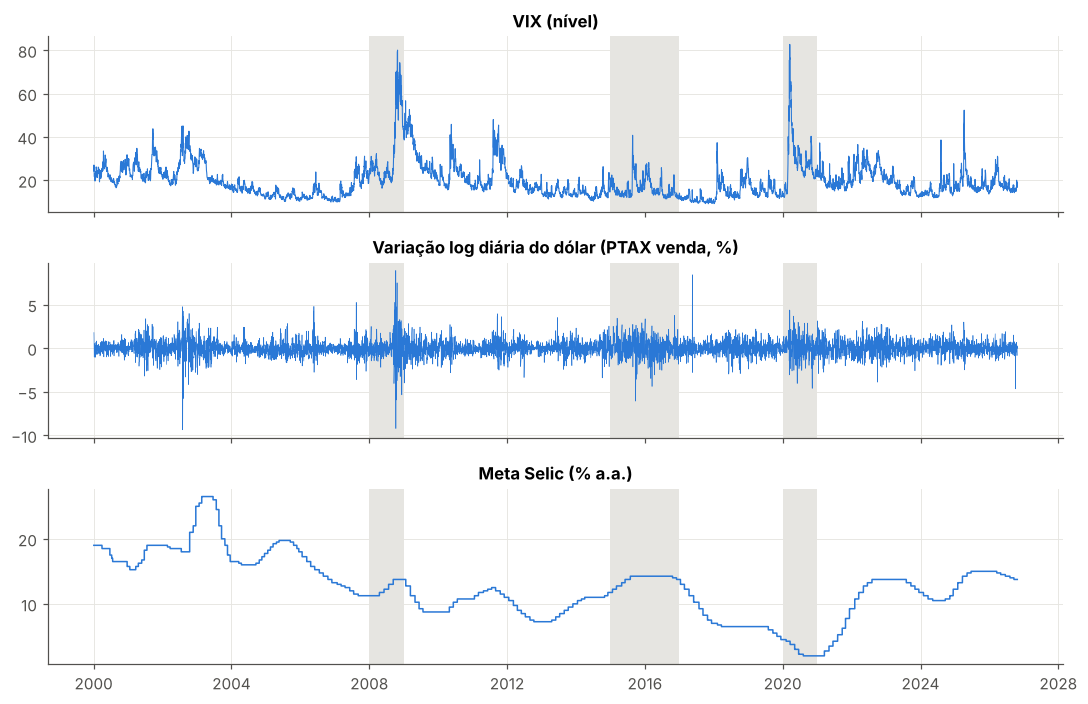

In [14]:
fig, axs = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
axs[0].plot(feats.index, np.exp(feats["log_vix"]), color=AZUL, lw=0.7)
axs[0].set_title("VIX (nível)")
axs[1].plot(feats.index, 100 * feats["dolar_var_log"], color=AZUL, lw=0.4)
axs[1].set_title("Variação log diária do dólar (PTAX venda, %)")
axs[2].step(feats.index, feats["selic_meta"], color=AZUL, lw=1.0, where="post")
axs[2].set_title("Meta Selic (% a.a.)")
for ax in axs:
    sombrear_estresse(ax)
fig.tight_layout()
salvar(fig, "eda_09_preditores")
plt.show()

,alvo h=1,alvo h=22
HAR diário (vol de hoje),0.50,0.53
HAR semanal (média 5 dias),0.59,0.66
HAR mensal (média 22 dias),0.56,0.67
Retorno do Ibovespa,-0.09,-0.05
log do VIX,0.36,0.41
Variação log do dólar,0.08,0.05
Meta Selic (nível),0.18,0.28
Meta Selic (variação),-0.00,0.00


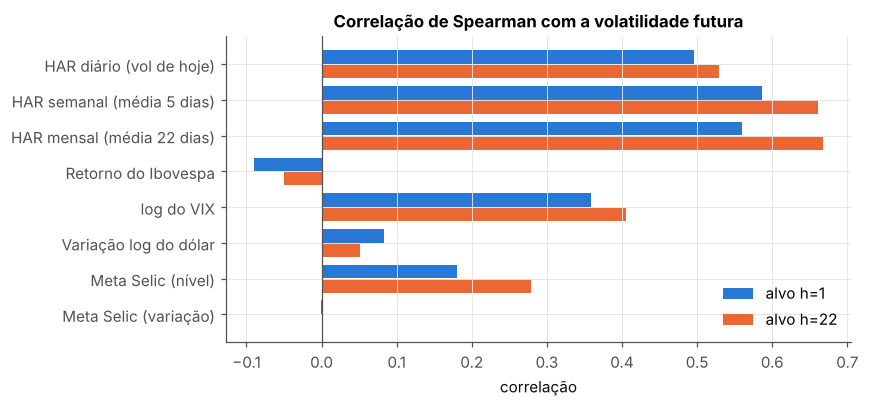

In [15]:
corr = feats[list(preditores) + ["alvo_h1", "alvo_h22"]].corr(method="spearman")[["alvo_h1", "alvo_h22"]]
corr = corr.loc[list(preditores)]
corr.index = [preditores[c] for c in corr.index]
corr.columns = ["alvo h=1", "alvo h=22"]
display(corr.round(2))

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(corr))
ax.barh(y - 0.2, corr["alvo h=1"], height=0.38, color=AZUL, label="alvo h=1")
ax.barh(y + 0.2, corr["alvo h=22"], height=0.38, color=LARANJA, label="alvo h=22")
ax.set_yticks(y, corr.index)
ax.invert_yaxis()
ax.axvline(0, color=CINZA, lw=0.8)
ax.set_title("Correlação de Spearman com a volatilidade futura")
ax.set_xlabel("correlação")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
salvar(fig, "eda_10_correlacoes")
plt.show()

**Leitura (rascunho):**
- Os três componentes do HAR são, de longe, os preditores mais correlacionados com a volatilidade futura. Isso reforça a memória longa da seção 4.
- O **VIX** tem correlação moderada: a volatilidade esperada do mercado americano carrega informação sobre o Ibovespa.
- A **variação do dólar** e o **retorno do Ibovespa** quase não se relacionam com a volatilidade futura nesta medida. No caso do retorno, a correlação levemente negativa é compatível com o "efeito alavancagem" (quedas seguidas de mais volatilidade). Mas o sinal é fraco aqui.
- O **nível da Selic** tem correlação positiva. Isso pode refletir só uma tendência comum: Selic e volatilidade eram ambas mais altas no começo da amostra. Não deve ser lido como efeito causal.
- A **variação da Selic** é zero em quase todos os dias e, sozinha, não se relaciona com a volatilidade futura. É candidata a sair do modelo, o que se avalia na Etapa 3.
- Correlação simples não mede o ganho de previsão **além** do HAR. É isso que o random forest testa no notebook de modelos.

## 8. Síntese e implicações para a modelagem

Ver os valores nas tabelas acima.

1. **Retornos:** caudas grossas e assimetria negativa. A normalidade é rejeitada.
2. **Volatilidade persistente:** os retornos ao quadrado e a volatilidade de Garman-Klass têm autocorrelação positiva que cai devagar. Isso justifica o HAR (médias de 1, 5 e 22 dias), e o ADF indica que o log da volatilidade é estacionário.
3. **Distribuição do alvo:** a volatilidade tem forte assimetria à direita, e o log dela é quase simétrico. O alvo continua em nível (% a.a.), conforme a decisão a. A assimetria é uma limitação a declarar: o MSE dá muito peso aos dias extremos.
4. **Estresse:** 2008 e 2020 têm volatilidade bem acima da média. **2015–2016 não**: foi uma crise macroeconômica e política, mas a volatilidade do Ibovespa ficou perto da média da amostra. Isso deve ser discutido ao testar a H3.
5. **Garman-Klass vs. retorno ao quadrado:** a diferença de nível é grande (cerca de 1,4 a 1,5 vez na variância) e não vem do salto noturno. O GARCH recebe um fator de escala calculado só no treino.
6. **Preditores:** os componentes HAR dominam, o VIX vem em seguida, e o dólar, o retorno e a variação da Selic são fracos.
7. **Qualidade:** sem preços inconsistentes nem dias de amplitude zero. Há 3 picos suspeitos em 2000–2001, mantidos e sinalizados.